# CardioIA: regressão logística versus LIF
**Guilherme Yamada Dantas — rm568506 | Ir Além 2**

Experimento didático com dados **100% sintéticos**, sem pacientes reais e sem validade diagnóstica. Uma série de BPM por indivíduo fictício, 180 amostras a 1 Hz. O rótulo identifica o cenário gerador de elevação prolongada; não significa doença. Os modelos não estão implantados no ESP32.

## Protocolo antes dos resultados
Semente 568506, 1.200 indivíduos, treino/validação/teste 60/20/20 estratificado. Nenhum indivíduo atravessa partições. StandardScaler é ajustado somente no treino. C ∈ {0,1; 1; 10} é selecionado por F1 de validação; limiar 0,5 fixo. Teste é usado somente para avaliar. O conjunto representa uma única distribuição artificial, não validação externa.

In [1]:
from pathlib import Path
import json, numpy as np, matplotlib.pyplot as plt
from experiment import generate, statistics, lif, run
# A implementação comentada está em experiment.py; a execução grava dataset e evidências.
results = run()
print(json.dumps({k:v for k,v in results.items() if k != 'split_ids'}, indent=2))

{
  "seed": 568506,
  "synthetic": true,
  "sampling_hz": 1,
  "window_seconds": 180,
  "split_sizes": {
    "train": 720,
    "validation": 240,
    "test": 240
  },
  "environment": {
    "python": "3.12.1",
    "numpy": "2.5.3",
    "sklearn": "1.6.0",
    "platform": "macOS-26.6.2-arm64-arm-64bit"
  },
  "models": {
    "logistic_statistics": {
      "accuracy": 0.8583333333333333,
      "precision": 0.8981481481481481,
      "recall": 0.8083333333333333,
      "f1": 0.8508771929824561,
      "roc_auc": 0.9429166666666666,
      "confusion_matrix_tn_fp_fn_tp": [
        109,
        11,
        23,
        97
      ],
      "selected_C": 10.0,
      "validation_f1": 0.8680851063829788,
      "feature_count": 8,
      "fit_seconds_selected": 0.0007927500118967146,
      "inference_batch_seconds_median": 0.00049591701827012,
      "inference_batch_size": 240,
      "validation_candidates": [
        {
          "C": 0.1,
          "f1": 0.8051948051948052
        },
        {
       

## Séries e modelos
A logística usa oito resumos: média, desvio, mínimo, máximo, percentil 90, proporção >120, diferença absoluta média e mudança entre primeiros/últimos 30 segundos.

O segundo método é **híbrido: banco LIF fixo + readout logístico treinável**, não uma SNN treinada ponta a ponta. São 3 canais × 4 ganhos × 2 constantes = 24 neurônios, Euler `v += (-v + I)/tau`, disparo em v ≥ 1 e reset v = 0. As taxas de spikes em três segmentos produzem 72 atributos. `dt=1` representa um passo normalizado por amostra, não milissegundos biológicos. O estado começa em zero para cada indivíduo. Não há STDP, FHN ou hardware neuromórfico.

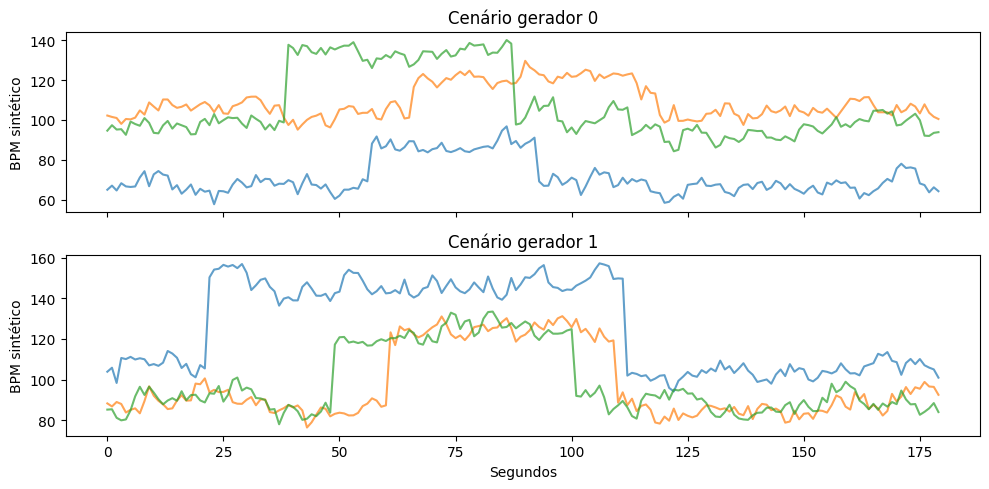

In [2]:
x,y = generate()
fig, ax = plt.subplots(2,1,figsize=(10,5),sharex=True)
for label in [0,1]:
    for idx in np.flatnonzero(y==label)[:3]: ax[label].plot(x[idx],alpha=.7)
    ax[label].set(ylabel='BPM sintético',title=f'Cenário gerador {label}')
ax[-1].set_xlabel('Segundos');fig.tight_layout()
fig.savefig('results/synthetic_examples.png',dpi=150)
plt.show()

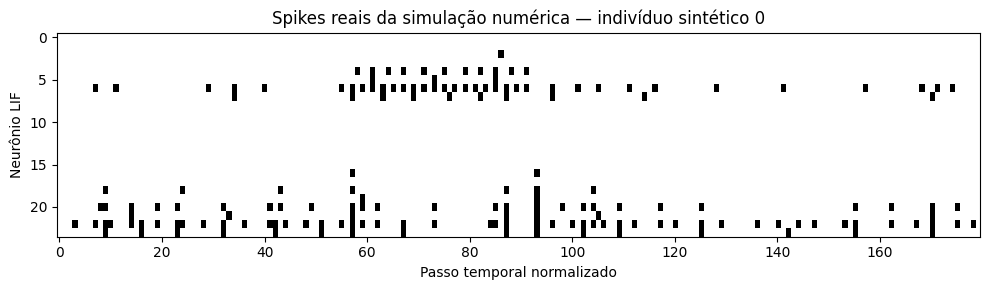

In [3]:
features,spikes = lif(x[:1],return_spikes=True)
fig, ax = plt.subplots(figsize=(10,3))
ax.imshow(spikes[0].T,aspect='auto',interpolation='nearest',cmap='Greys')
ax.set(xlabel='Passo temporal normalizado',ylabel='Neurônio LIF',title='Spikes reais da simulação numérica — indivíduo sintético 0')
fig.tight_layout();fig.savefig('results/lif_spikes.png',dpi=150);plt.show()
assert features.shape == (1,72)
assert set(results['split_ids']['train']).isdisjoint(results['split_ids']['test'])

## Comparação e limites
Abaixo estão resultados efetivamente calculados no teste. A matriz é [TN, FP, FN, TP]. O tempo inclui transformação das séries e inferência de um lote de 240 janelas, mediana de sete repetições no computador local. Não inclui captura de 180 segundos, MQTT ou execução embarcada. Não houve medição de energia; latência não pode substituí-la.

In [4]:
for name,m in results['models'].items():
    print(name)
    print({k:round(m[k],4) for k in ['accuracy','precision','recall','f1','roc_auc']})
    print('Matriz TN FP FN TP:',m['confusion_matrix_tn_fp_fn_tp'])
    print('Tempo lote (ms):',round(m['inference_batch_seconds_median']*1000,3))
# Testes reais, separados da avaliação dos classificadores.
import unittest
from test_experiment import ExperimentTests
suite=unittest.defaultTestLoader.loadTestsFromTestCase(ExperimentTests)
check=unittest.TextTestRunner(verbosity=2).run(suite)
assert check.wasSuccessful()

test_features_finite (test_experiment.ExperimentTests.test_features_finite) ... 

ok


test_generator_reproducible_and_balanced (test_experiment.ExperimentTests.test_generator_reproducible_and_balanced) ... 

ok


test_lif_silent_and_active (test_experiment.ExperimentTests.test_lif_silent_and_active) ... 

ok


test_lif_state_does_not_leak_between_individuals (test_experiment.ExperimentTests.test_lif_state_does_not_leak_between_individuals) ... 

ok


----------------------------------------------------------------------
Ran 4 tests in 0.091s

OK


logistic_statistics
{'accuracy': 0.8583, 'precision': 0.8981, 'recall': 0.8083, 'f1': 0.8509, 'roc_auc': np.float64(0.9429)}
Matriz TN FP FN TP: [109, 11, 23, 97]
Tempo lote (ms): 0.496
lif_logistic_readout
{'accuracy': 0.7625, 'precision': 0.7692, 'recall': 0.75, 'f1': 0.7595, 'roc_auc': np.float64(0.8225)}
Matriz TN FP FN TP: [93, 27, 30, 90]
Tempo lote (ms): 7.116


## Análise crítica e próximos passos
Os métodos comparam representações diferentes, e não isolam o efeito da arquitetura. Boa pontuação pode refletir a facilidade do gerador. Uma única semente não caracteriza a variância. O banco LIF é simulado em CPU convencional; não se demonstrou vantagem energética, clínica ou operacional. Antes de uso real seriam necessários dados consentidos, validação externa e temporal, avaliação por paciente, calibração, análise de erro e medição no hardware-alvo.

## Referências
- FIAP, Fase 3, Cap03, *Cérebros de Silício na Era dos Chips Neuromórficos*, seções 3.1–3.3: relação entre arquitetura e consumo energético. Ebook local consultado; não redistribuído.
- [Gerstner et al., Neuronal Dynamics, seção 1.3](https://neuronaldynamics.epfl.ch/online/Ch1.S3.html): integração, limiar e reset LIF.
- [scikit-learn LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

Vídeo de até quatro minutos e publicação não listada no YouTube: pendentes de gravação/ação humana; nenhum link é inventado.